# Retail Customer Retention Intelligence
## Phase 2 — Exploratory Data Analysis and Statistical Testing

This phase explores customer purchasing behavior statistically before predictive modeling.

The goals are to:

- inspect customer-level distributions;
- compare one-time and repeat customers;
- examine spending, frequency, and recency behavior;
- quantify uncertainty using confidence intervals;
- test whether observed customer-group differences are statistically meaningful;
- report effect sizes alongside p-values.

Statistical tests will be selected based on the observed data distributions rather than assumed in advance.

### 2.1 Environment Setup and Database Connection

In [6]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sqlalchemy import create_engine, text
from dotenv import load_dotenv


# Locate project root and load local environment variables.
PROJECT_ROOT = Path.cwd().parent
load_dotenv(PROJECT_ROOT / ".env")


# Create PostgreSQL connection.
DATABASE_URL = (
    f"postgresql+psycopg2://{os.getenv('DB_USER')}:"
    f"{os.getenv('DB_PASSWORD')}@"
    f"{os.getenv('DB_HOST')}:"
    f"{os.getenv('DB_PORT')}/"
    f"{os.getenv('DB_NAME')}"
)

engine = create_engine(DATABASE_URL)

print("Environment ready.")

Environment ready.


### 2.2 Build the Customer-Level Analytical Dataset

Transaction-level data is aggregated to one row per customer so purchasing behavior can be analyzed statistically.

The customer-level dataset includes:

- number of orders;
- total merchandise revenue;
- average order value;
- total units purchased;
- first and most recent purchase dates;
- purchase recency;
- observed customer lifespan;
- whether the customer made repeat purchases.

In [7]:
customer_summary_query = """
WITH invoice_level AS (
    SELECT
        customer_id,
        invoice,
        MIN(invoice_date) AS invoice_date,
        SUM(quantity) AS units,
        SUM(line_revenue) AS order_revenue
    FROM retail_transactions
    GROUP BY customer_id, invoice
),

dataset_end AS (
    SELECT MAX(invoice_date)::date AS reference_date
    FROM retail_transactions
)

SELECT
    i.customer_id,
    COUNT(*) AS order_count,
    SUM(i.units) AS total_units,
    ROUND(SUM(i.order_revenue), 2) AS total_revenue,
    ROUND(AVG(i.order_revenue), 2) AS avg_order_value,
    MIN(i.invoice_date) AS first_purchase,
    MAX(i.invoice_date) AS last_purchase,
    d.reference_date - MAX(i.invoice_date)::date AS recency_days,
    MAX(i.invoice_date)::date - MIN(i.invoice_date)::date AS customer_lifespan_days,
    CASE
        WHEN COUNT(*) > 1 THEN 1
        ELSE 0
    END AS repeat_customer
FROM invoice_level i
CROSS JOIN dataset_end d
GROUP BY
    i.customer_id,
    d.reference_date
ORDER BY i.customer_id;
"""

with engine.connect() as connection:
    customer_summary = pd.read_sql(
        text(customer_summary_query),
        connection
    )

print("Customer-level shape:", customer_summary.shape)
customer_summary.head()

Customer-level shape: (5861, 10)


,customer_id,order_count,total_units,total_revenue,avg_order_value,first_purchase,last_purchase,recency_days,customer_lifespan_days,repeat_customer
0,12346,3,74239.0,77352.96,25784.32,2010-03-02 13:08:00,2011-01-18 10:01:00,325,322,1
1,12347,8,2967.0,4921.53,615.19,2010-10-31 14:20:00,2011-12-07 15:52:00,2,402,1
2,12348,5,2704.0,1658.40,331.68,2010-09-27 14:59:00,2011-09-25 13:13:00,75,363,1
3,12349,3,1621.0,3678.69,1226.23,2010-04-29 13:20:00,2011-11-21 09:51:00,18,571,1
4,12350,1,196.0,294.40,294.40,2011-02-02 16:01:00,2011-02-02 16:01:00,310,0,0


### 2.3 Customer Behavior Distributions

Descriptive statistics are used to examine the scale, spread, and skewness of customer purchasing behavior before selecting appropriate statistical tests.

In [8]:
# Convert PostgreSQL numeric columns to standard floating-point values
# for statistical analysis and visualization.
customer_summary["total_revenue"] = customer_summary["total_revenue"].astype(float)
customer_summary["avg_order_value"] = customer_summary["avg_order_value"].astype(float)

numeric_columns = [
    "order_count",
    "total_units",
    "total_revenue",
    "avg_order_value",
    "recency_days",
    "customer_lifespan_days",
]

customer_descriptive_stats = (
    customer_summary[numeric_columns]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
    .T
)

customer_descriptive_stats

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
order_count,5861.0,6.249616,12.774814,1.00,1.00,3.00,7.00,13.00,20.0,46.000,376.00
total_units,5861.0,1791.293807,8884.321230,1.00,188.00,484.00,1351.00,3175.00,5354.0,16707.000,367072.00
total_revenue,5861.0,2912.958930,14300.362807,2.95,338.13,854.99,2237.12,5381.08,9266.0,28616.334,580987.04
avg_order_value,5861.0,383.821706,1253.772229,2.95,175.87,277.40,409.98,623.50,869.3,1891.538,84236.25
recency_days,5861.0,200.472957,209.217206,0.00,25.00,95.00,379.00,534.00,625.0,726.000,738.00
customer_lifespan_days,5861.0,273.558949,258.668897,0.00,0.00,222.00,512.00,667.00,713.0,732.000,738.00


#### Interpretation

Customer purchasing behavior is highly skewed.

- **Order frequency** has a median of 3 orders, while the mean is 6.25 and the maximum is 376, indicating a small group of extremely frequent buyers.
- **Total revenue** has a median of approximately **£855**, compared with a mean of about **£2,913** and a maximum above **£580,000**.
- **Average order value** is also strongly right-skewed, with a median of about **£277** but a maximum above **£84,000**.
- Large differences between the median, upper percentiles, and maximum values indicate substantial customer-level outliers.
- Median customer recency is **95 days**, while 25% of customers purchased within the last 25 days.
- Customer lifespan has a lower quartile of 0 days because one-time customers have the same first and last purchase date.

Because several variables are strongly skewed, statistical comparisons should not rely only on means or assume normally distributed data. Robust summaries, visual inspection, and non-parametric tests will be considered where appropriate.

#### 2.3.1 Distribution of Customer Purchase Behavior

Histograms are used to inspect the shape and skewness of the primary customer-level purchasing metrics. Logarithmic transformations are used for highly right-skewed monetary and frequency variables to make the underlying distributions easier to inspect.

In [9]:
# Create log-transformed versions for visualization only.
customer_summary["log_order_count"] = np.log1p(
    customer_summary["order_count"]
)

customer_summary["log_total_units"] = np.log1p(
    customer_summary["total_units"]
)

customer_summary["log_total_revenue"] = np.log1p(
    customer_summary["total_revenue"]
)

customer_summary["log_avg_order_value"] = np.log1p(
    customer_summary["avg_order_value"]
)

#### 2.3.2 Skewness of Customer Metrics

Skewness is calculated to quantify how asymmetric each customer-level variable is.

As a rough guideline:

- absolute skewness below **0.5** → approximately symmetric;
- **0.5 to 1.0** → moderately skewed;
- above **1.0** → highly skewed.

In [10]:
# Measure the skewness of the main customer-level variables.
skewness_results = (
    customer_summary[numeric_columns]
    .skew()
    .sort_values(ascending=False)
    .to_frame(name="skewness")
)

skewness_results

,skewness
avg_order_value,53.422676
total_revenue,25.343303
total_units,21.839651
order_count,12.108235
recency_days,0.892268
customer_lifespan_days,0.386605


#### Interpretation

The calculated skewness confirms that several customer purchasing metrics are strongly asymmetric.

- **Average order value (53.42)**, **total revenue (25.34)**, **total units (21.84)**, and **order count (12.11)** are extremely right-skewed.
- This reflects a small number of customers with exceptionally high spending, purchase volume, or frequency.
- **Recency (0.89)** is moderately right-skewed, indicating a longer tail of customers with extended inactivity.
- **Customer lifespan (0.39)** is comparatively less skewed.

Because the main purchasing variables are far from symmetric, medians and percentile-based summaries are more representative of typical customer behavior than means alone. Statistical comparisons involving these variables should also avoid assuming normality without further evidence.

#### 2.3.3 Log-Transformed Variables for Visualization

Highly right-skewed variables are log-transformed using `log1p()` to compress extreme values and make their distributions easier to visualize.

The original variables are preserved; the transformed columns are created only for exploratory visualization.

In [11]:
# Create log-transformed versions for visualization only.
customer_summary["log_order_count"] = np.log1p(
    customer_summary["order_count"]
)

customer_summary["log_total_units"] = np.log1p(
    customer_summary["total_units"]
)

customer_summary["log_total_revenue"] = np.log1p(
    customer_summary["total_revenue"]
)

customer_summary["log_avg_order_value"] = np.log1p(
    customer_summary["avg_order_value"]
)

#### 2.3.4 Customer Revenue Distribution

The raw and log-transformed customer revenue distributions are compared to visualize the effect of extreme high-value customers.

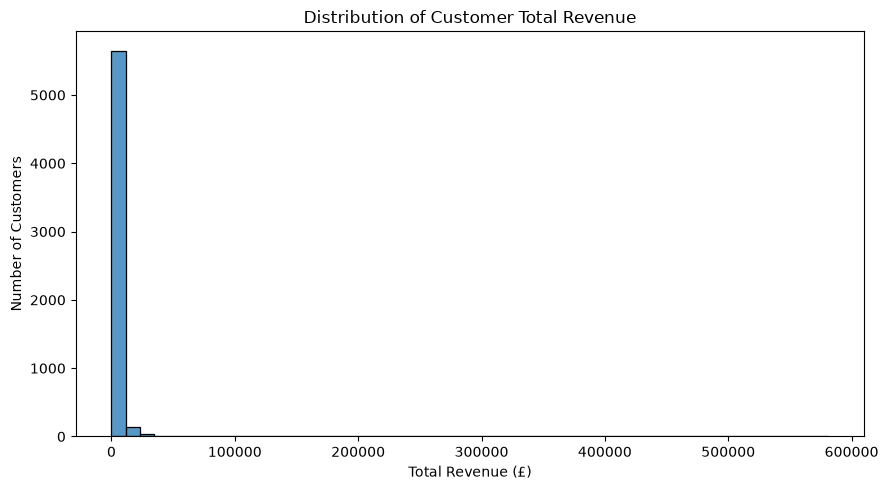

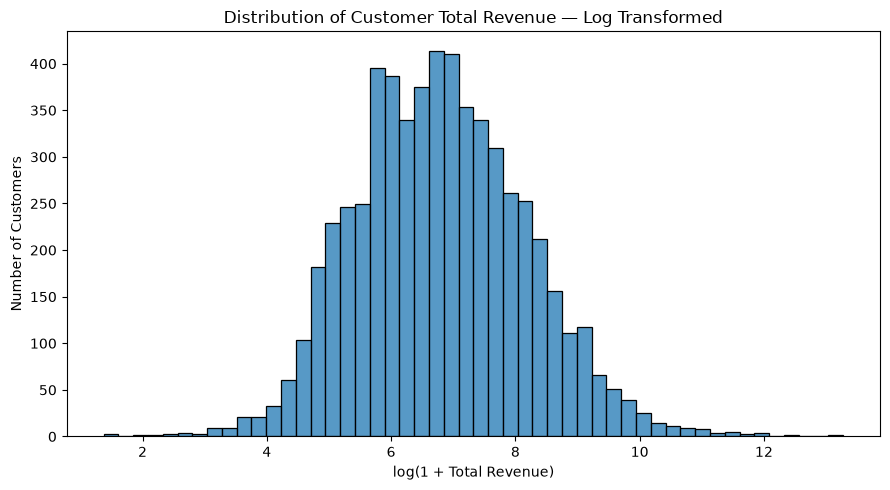

In [12]:
# Raw customer revenue distribution.
plt.figure(figsize=(9, 5))

sns.histplot(
    data=customer_summary,
    x="total_revenue",
    bins=50
)

plt.title("Distribution of Customer Total Revenue")
plt.xlabel("Total Revenue (£)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


# Log-transformed customer revenue distribution.
plt.figure(figsize=(9, 5))

sns.histplot(
    data=customer_summary,
    x="log_total_revenue",
    bins=50
)

plt.title("Distribution of Customer Total Revenue — Log Transformed")
plt.xlabel("log(1 + Total Revenue)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [13]:
customer_summary["total_revenue"].max()

np.float64(580987.04)

#### Interpretation

The raw customer revenue distribution is extremely right-skewed.

- Most customers generate relatively modest total revenue and are concentrated near the left side of the distribution.
- A very small number of exceptionally high-value customers extend the distribution far to the right, with the maximum customer revenue exceeding £580,000.
- These extreme values explain the very high raw revenue skewness of **25.34**.

After applying `log1p()`, the distribution becomes much more balanced and its underlying shape is easier to inspect.

The transformation compresses extreme revenue values while preserving their ordering. It is useful for visualization and may also be useful for some modeling methods later, but the original revenue values remain unchanged.

### 2.4 One-Time vs Repeat Customer Behavior

Customer behavior is compared between customers who made only one observed merchandise purchase and customers who returned for additional purchases.

The analysis focuses on differences in spending, purchase volume, and recency before formal statistical testing.

#### 2.4.1 Descriptive Comparison


In [14]:
group_summary = (
    customer_summary
    .groupby("repeat_customer")
    .agg(
        customers=("customer_id", "count"),
        median_revenue=("total_revenue", "median"),
        mean_revenue=("total_revenue", "mean"),
        median_avg_order_value=("avg_order_value", "median"),
        median_units=("total_units", "median"),
        median_recency=("recency_days", "median"),
    )
    .round(2)
)

group_summary.index = [
    "One-time customer",
    "Repeat customer"
]

group_summary

,customers,median_revenue,mean_revenue,median_avg_order_value,median_units,median_recency
One-time customer,1625,227.10,342.25,227.10,130.0,386.0
Repeat customer,4236,1363.86,3899.13,291.08,794.0,59.0


#### Interpretation

Repeat customers show substantially stronger purchasing activity than one-time customers.

- Repeat customers have a median total revenue of **£1,363.86**, compared with **£227.10** for one-time customers.
- Their median purchase volume is also much higher: **794 units** compared with **130 units**.
- Median average order value differs less dramatically, at **£291.08** for repeat customers versus **£227.10** for one-time customers.
- Repeat customers are considerably more recent, with a median recency of **59 days**, compared with **386 days** for one-time customers.
- Mean revenue is much higher than median revenue in both groups, especially among repeat customers, reflecting the strong right-skew and presence of very high-value customers.

The large difference in total revenue is partly structural because repeat customers, by definition, have multiple orders and therefore more opportunities to accumulate revenue. Average order value and recency provide more informative behavioral comparisons between the groups.

#### 2.4.2 Statistical Comparison of Average Order Value

Because average order value is extremely right-skewed, a Mann–Whitney U test is used to compare one-time and repeat customers without assuming normally distributed values.

The analysis reports both statistical significance and effect size because a small p-value alone does not indicate whether the observed difference is practically meaningful.

In [15]:
# Separate average order values for the two independent customer groups.
one_time_aov = customer_summary.loc[
    customer_summary["repeat_customer"] == 0,
    "avg_order_value"
]

repeat_aov = customer_summary.loc[
    customer_summary["repeat_customer"] == 1,
    "avg_order_value"
]


# Mann–Whitney U test.
u_statistic, p_value = stats.mannwhitneyu(
    repeat_aov,
    one_time_aov,
    alternative="two-sided"
)


# Rank-biserial correlation as an effect-size measure.
n_repeat = len(repeat_aov)
n_one_time = len(one_time_aov)

rank_biserial = (
    2 * u_statistic / (n_repeat * n_one_time)
) - 1


print(f"Repeat customers: {n_repeat:,}")
print(f"One-time customers: {n_one_time:,}")
print(f"Mann–Whitney U: {u_statistic:,.0f}")
print(f"P-value: {p_value:.6g}")
print(f"Rank-biserial correlation: {rank_biserial:.3f}")

Repeat customers: 4,236
One-time customers: 1,625
Mann–Whitney U: 4,105,272
P-value: 2.56638e-30
Rank-biserial correlation: 0.193


#### Interpretation

The Mann–Whitney U test found strong statistical evidence of a difference in average order value between one-time and repeat customers.

- **Mann–Whitney U:** 4,105,272
- **p-value:** 2.57 × 10⁻³⁰
- **Rank-biserial correlation:** 0.193

Because the p-value is far below 0.05, the null hypothesis of no systematic difference between the groups is rejected.

The positive rank-biserial correlation indicates that repeat customers tend to have higher average order values. However, the effect size of **0.193 is relatively small**, meaning the difference is statistically clear but modest in magnitude.

This distinction is important: the large sample size provides strong evidence that a difference exists, while the effect size shows that average order value alone does not strongly separate one-time and repeat customers.

#### 2.4.3 Confidence Interval for the Median AOV Difference

A bootstrap confidence interval is used to estimate the uncertainty around the difference in median average order value between repeat and one-time customers.

Bootstrapping repeatedly resamples customers with replacement and recalculates the median difference without requiring a normal distribution.

In [16]:
# Observed difference in median average order value.
observed_median_difference = (
    repeat_aov.median() - one_time_aov.median()
)

# Reproducible random-number generator.
rng = np.random.default_rng(42)

n_bootstrap = 5000
bootstrap_differences = np.empty(n_bootstrap)

# Repeatedly resample both customer groups and calculate
# the difference between their median average order values.
for i in range(n_bootstrap):
    repeat_sample = rng.choice(
        repeat_aov,
        size=len(repeat_aov),
        replace=True
    )

    one_time_sample = rng.choice(
        one_time_aov,
        size=len(one_time_aov),
        replace=True
    )

    bootstrap_differences[i] = (
        np.median(repeat_sample)
        - np.median(one_time_sample)
    )

# Percentile-based 95% bootstrap confidence interval.
ci_lower, ci_upper = np.percentile(
    bootstrap_differences,
    [2.5, 97.5]
)

print(
    f"Observed median difference: "
    f"£{observed_median_difference:.2f}"
)
print(
    f"95% bootstrap CI: "
    f"[£{ci_lower:.2f}, £{ci_upper:.2f}]"
)

Observed median difference: £63.98
95% bootstrap CI: [£50.78, £77.26]


#### Interpretation

Repeat customers have a median average order value that is **£63.98 higher** than one-time customers.

The **95% bootstrap confidence interval** for this difference is:

**£50.78 to £77.26**

Because the entire interval is above £0, the result supports the conclusion that repeat customers tend to have higher average order values.

The interval also shows the uncertainty around the estimate: while the observed difference is about £64, the plausible difference supported by the bootstrap is roughly between £51 and £77.

### 2.5 Relationships Between Customer Metrics

Relationships between customer purchasing metrics are examined using Spearman rank correlation.

Spearman correlation is appropriate here because several variables are strongly skewed and it measures monotonic relationships without requiring normally distributed data.

#### 2.5.1 Spearman Correlation Matrix

In [17]:
# Customer metrics used for correlation analysis.
correlation_columns = [
    "order_count",
    "total_units",
    "total_revenue",
    "avg_order_value",
    "recency_days",
    "customer_lifespan_days",
]

# Spearman correlation is used because several variables
# are strongly skewed and contain extreme values.
spearman_corr = customer_summary[
    correlation_columns
].corr(method="spearman")

spearman_corr.round(3)

,order_count,total_units,total_revenue,avg_order_value,recency_days,customer_lifespan_days
order_count,1.000,0.818,0.859,0.211,-0.559,0.882
total_units,0.818,1.000,0.946,0.612,-0.513,0.730
total_revenue,0.859,0.946,1.000,0.651,-0.511,0.766
avg_order_value,0.211,0.612,0.651,1.000,-0.174,0.211
recency_days,-0.559,-0.513,-0.511,-0.174,1.000,-0.568
customer_lifespan_days,0.882,0.730,0.766,0.211,-0.568,1.000


#### Interpretation

The Spearman correlation matrix shows several strong relationships in customer purchasing behavior.

- **Total units and total revenue (0.946)** have the strongest positive relationship. Customers who purchase more units generally generate more revenue.
- **Order count and customer lifespan (0.882)** are also strongly related. Customers observed over longer purchasing periods tend to place more orders.
- **Order count and total revenue (0.859)** show that more frequent customers generally generate substantially more revenue.
- **Order count and total units (0.818)** are strongly positively related.
- **Average order value and total revenue (0.651)** have a moderate-to-strong positive relationship, although purchasing frequency also contributes substantially to total customer value.
- **Recency is negatively related to order count (-0.559), total revenue (-0.511), and customer lifespan (-0.568)**. Customers who purchased more recently tend to have greater historical engagement and value.

These correlations describe associations rather than causal relationships. Some relationships are also structurally expected; for example, total revenue naturally increases as customers purchase more units or place more orders.

#### 2.5.2 Correlation Heatmap

A heatmap is used to visualize the direction and strength of the Spearman correlations between customer metrics.

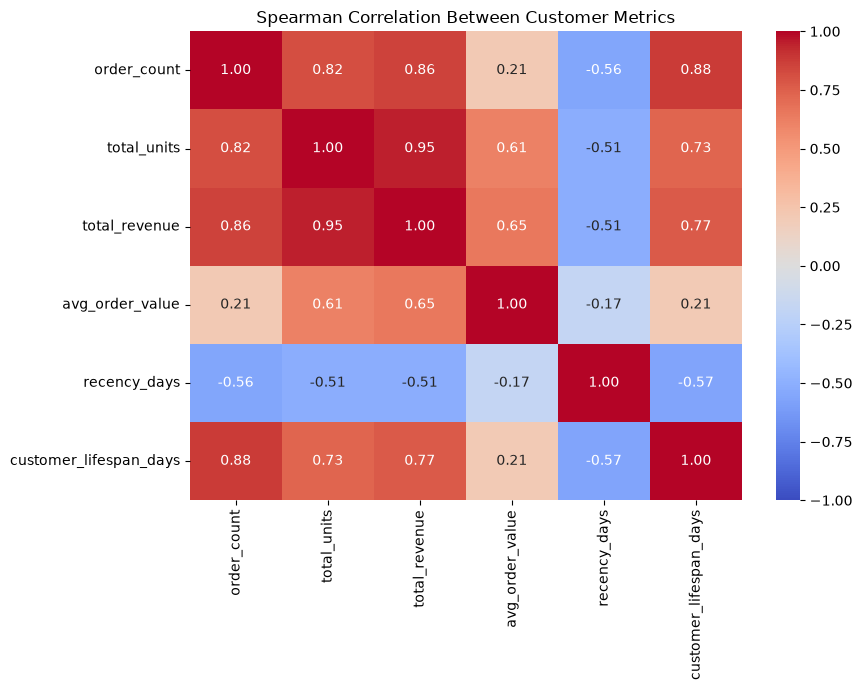

In [18]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Spearman Correlation Between Customer Metrics")
plt.tight_layout()
plt.show()

#### Interpretation

The heatmap visually confirms the correlation patterns identified in the numerical matrix.

- Customer value metrics such as **order count, total units, and total revenue** are strongly positively related.
- **Total units and total revenue** show the strongest relationship (`0.95`).
- **Order count and customer lifespan** are also strongly related (`0.88`), suggesting that longer-standing customers tend to purchase more frequently.
- **Recency is negatively associated** with order frequency, revenue, and lifespan. Customers who have been inactive for longer generally show lower historical engagement.
- Average order value has weaker relationships with order frequency and customer lifespan, suggesting that customer value is driven more strongly by repeated purchasing than by unusually large individual orders.

These correlations describe associations and should not be interpreted as evidence of causation.

### 2.6 Phase 2 Summary

The exploratory and statistical analysis produced several key findings:

- Customer purchasing behavior is highly right-skewed, with a relatively small group of customers accounting for extreme levels of spending and activity.
- Repeat customers show substantially greater total revenue, purchase volume, and recent activity than one-time customers.
- Repeat customers also have a higher median average order value by approximately **£63.98**.
- The Mann–Whitney U test found very strong statistical evidence of an average-order-value difference between one-time and repeat customers (`p ≈ 2.57 × 10⁻³⁰`).
- The rank-biserial effect size (`0.193`) indicates that this difference is statistically clear but modest in magnitude.
- The 95% bootstrap confidence interval for the median AOV difference is **£50.78 to £77.26**, supporting a positive difference between the groups.
- Order frequency, purchase volume, revenue, and customer lifespan are strongly related.
- Longer recency is associated with lower historical engagement and customer value.

These findings support the use of recency, frequency, monetary value, and customer tenure-related behavior in the segmentation and churn-modeling phases that follow.